In [ ]:
import numpy as np #NumPy for numerical calculations and random data generation,
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats #SciPy for probability distributions
import pandas as pd

In [ ]:
np.random.seed(42)

In [ ]:
print("=" * 60)
print("NORMAL DISTRIBUTION  N(μ, σ²)")
print("=" * 60)

NORMAL DISTRIBUTION  N(μ, σ²)


In [ ]:
params = [(0, 1), (2, 1), (0, 2), (-2, 0.5)]
x = np.linspace(-8, 8, 400)

In [ ]:
print("\nNormal Distribution Properties:")
for mu, sigma in params:
    dist = stats.norm(mu, sigma)
    print(f"\n  N(μ={mu}, σ={sigma}):")
    print(f"  Mean={dist.mean():.2f}, Var={dist.var():.2f},"
          f" Skew={dist.stats('s'):.2f},"
          f" Kurt={dist.stats('k'):.2f}")


Normal Distribution Properties:

  N(μ=0, σ=1):
  Mean=0.00, Var=1.00, Skew=0.00, Kurt=0.00

  N(μ=2, σ=1):
  Mean=2.00, Var=1.00, Skew=0.00, Kurt=0.00

  N(μ=0, σ=2):
  Mean=0.00, Var=4.00, Skew=0.00, Kurt=0.00

  N(μ=-2, σ=0.5):
  Mean=-2.00, Var=0.25, Skew=0.00, Kurt=0.00


In [ ]:
# Standard Normal — 68-95-99.7 Rule
std_normal = stats.norm(0, 1)
print("\n68-95-99.7 Rule Verification:")
print(f"  P(-1 < Z < 1)  = {std_normal.cdf(1) - std_normal.cdf(-1):.6f} ≈ 68.27%")
print(f"  P(-2 < Z < 2)  = {std_normal.cdf(2) - std_normal.cdf(-2):.6f} ≈ 95.45%")
print(f"  P(-3 < Z < 3)  = {std_normal.cdf(3) - std_normal.cdf(-3):.6f} ≈ 99.73%")



68-95-99.7 Rule Verification:
  P(-1 < Z < 1)  = 0.682689 ≈ 68.27%
  P(-2 < Z < 2)  = 0.954500 ≈ 95.45%
  P(-3 < Z < 3)  = 0.997300 ≈ 99.73%


In [ ]:
# Z-score and Standardization
print("\nZ-score Examples:")
raw_scores = [60, 70, 80, 90]
mu_exam, sigma_exam = 70, 10
for score in raw_scores:
    z = (score - mu_exam) / sigma_exam
    percentile = std_normal.cdf(z) * 100
    print(f"  Score={score}, Z={z:.2f}, Percentile={percentile:.1f}%")



Z-score Examples:
  Score=60, Z=-1.00, Percentile=15.9%
  Score=70, Z=0.00, Percentile=50.0%
  Score=80, Z=1.00, Percentile=84.1%
  Score=90, Z=2.00, Percentile=97.7%


In [ ]:
# ML Context: Weight initialization
print("\n  ML Context — Weight Initialization:")
print(f"  Xavier init: W ~ N(0, 2/(n_in + n_out))")
n_in, n_out = 784, 128
xavier_std = np.sqrt(2 / (n_in + n_out))
print(f"  For Dense(784→128): σ = {xavier_std:.6f}")



  ML Context — Weight Initialization:
  Xavier init: W ~ N(0, 2/(n_in + n_out))
  For Dense(784→128): σ = 0.046829


In [ ]:
print("\n" + "=" * 60)
print("EXPONENTIAL DISTRIBUTION  Exp(λ)")
print("=" * 60)



EXPONENTIAL DISTRIBUTION  Exp(λ)


In [ ]:
lambdas_exp = [0.5, 1.0, 2.0, 3.0]
x_exp = np.linspace(0, 8, 300)


In [ ]:
for lam in lambdas_exp:
    dist_e = stats.expon(scale=1/lam)
    print(f"\n  Exp(λ={lam}): Mean={dist_e.mean():.4f},"
          f" Var={dist_e.var():.4f},"
          f" Std={dist_e.std():.4f}")



  Exp(λ=0.5): Mean=2.0000, Var=4.0000, Std=2.0000

  Exp(λ=1.0): Mean=1.0000, Var=1.0000, Std=1.0000

  Exp(λ=2.0): Mean=0.5000, Var=0.2500, Std=0.5000

  Exp(λ=3.0): Mean=0.3333, Var=0.1111, Std=0.3333


In [ ]:
lam_main = 1.0
exp_main = stats.expon(scale=1/lam_main)
exp_data = np.random.exponential(1/lam_main, 5000)
print(f"\n  Memoryless Property (λ={lam_main}):")
print(f"  P(X > 2)            = {1 - exp_main.cdf(2):.6f}")
print(f"  P(X > 3 | X > 1)    = {(1 - exp_main.cdf(3)) / (1 - exp_main.cdf(1)):.6f}")
print(f"  Both equal? {abs((1-exp_main.cdf(2)) - (1-exp_main.cdf(3))/(1-exp_main.cdf(1))) < 1e-9}")



  Memoryless Property (λ=1.0):
  P(X > 2)            = 0.135335
  P(X > 3 | X > 1)    = 0.135335
  Both equal? True


In [ ]:
print("\n" + "=" * 60)
print("CENTRAL LIMIT THEOREM SIMULATION")
print("=" * 60)



CENTRAL LIMIT THEOREM SIMULATION


In [ ]:
distributions_clt = {
    'Uniform(0,1)': lambda n: np.random.uniform(0, 1, n),
    'Exponential(1)': lambda n: np.random.exponential(1, n),
    'Binomial(10,0.3)': lambda n: np.random.binomial(10, 0.3, n)
}


In [ ]:
sample_sizes = [1, 5, 30, 100]
for dist_name, sampler in distributions_clt.items():
    print(f"\n  {dist_name}:")
    for n in sample_sizes:
        sample_means = [np.mean(sampler(n)) for _ in range(2000)]
        print(f"    n={n:>3}: mean={np.mean(sample_means):.4f},"
              f" std={np.std(sample_means):.4f}")



  Uniform(0,1):
    n=  1: mean=0.4921, std=0.2968
    n=  5: mean=0.4993, std=0.1308
    n= 30: mean=0.5000, std=0.0521
    n=100: mean=0.4990, std=0.0287

  Exponential(1):
    n=  1: mean=1.0450, std=1.0540
    n=  5: mean=0.9946, std=0.4552
    n= 30: mean=1.0033, std=0.1845
    n=100: mean=1.0002, std=0.1024

  Binomial(10,0.3):
    n=  1: mean=3.0155, std=1.4650
    n=  5: mean=3.0073, std=0.6301
    n= 30: mean=2.9985, std=0.2653
    n=100: mean=2.9980, std=0.1432


In [ ]:
print("\n" + "=" * 60)
print("MOMENTS ANALYSIS")
print("=" * 60)


MOMENTS ANALYSIS


In [ ]:
print("\nRaw Moments E[Xᵏ]:")
dist_norm = stats.norm(0, 1)
for k in range(1, 5):
    raw_moment = dist_norm.moment(k)
    print(f"  E[X^{k}] = {raw_moment:.6f}")



Raw Moments E[Xᵏ]:
  E[X^1] = 0.000000
  E[X^2] = 1.000000
  E[X^3] = 0.000000
  E[X^4] = 3.000000


In [ ]:
print("\nCentral Moments:")
data_sample = np.random.normal(5, 2, 1000)
for k in range(1, 5):
    central = np.mean((data_sample - np.mean(data_sample))**k)
    print(f"  μ_{k} = {central:.6f}")



Central Moments:
  μ_1 = 0.000000
  μ_2 = 3.991634
  μ_3 = -1.367958
  μ_4 = 49.909992


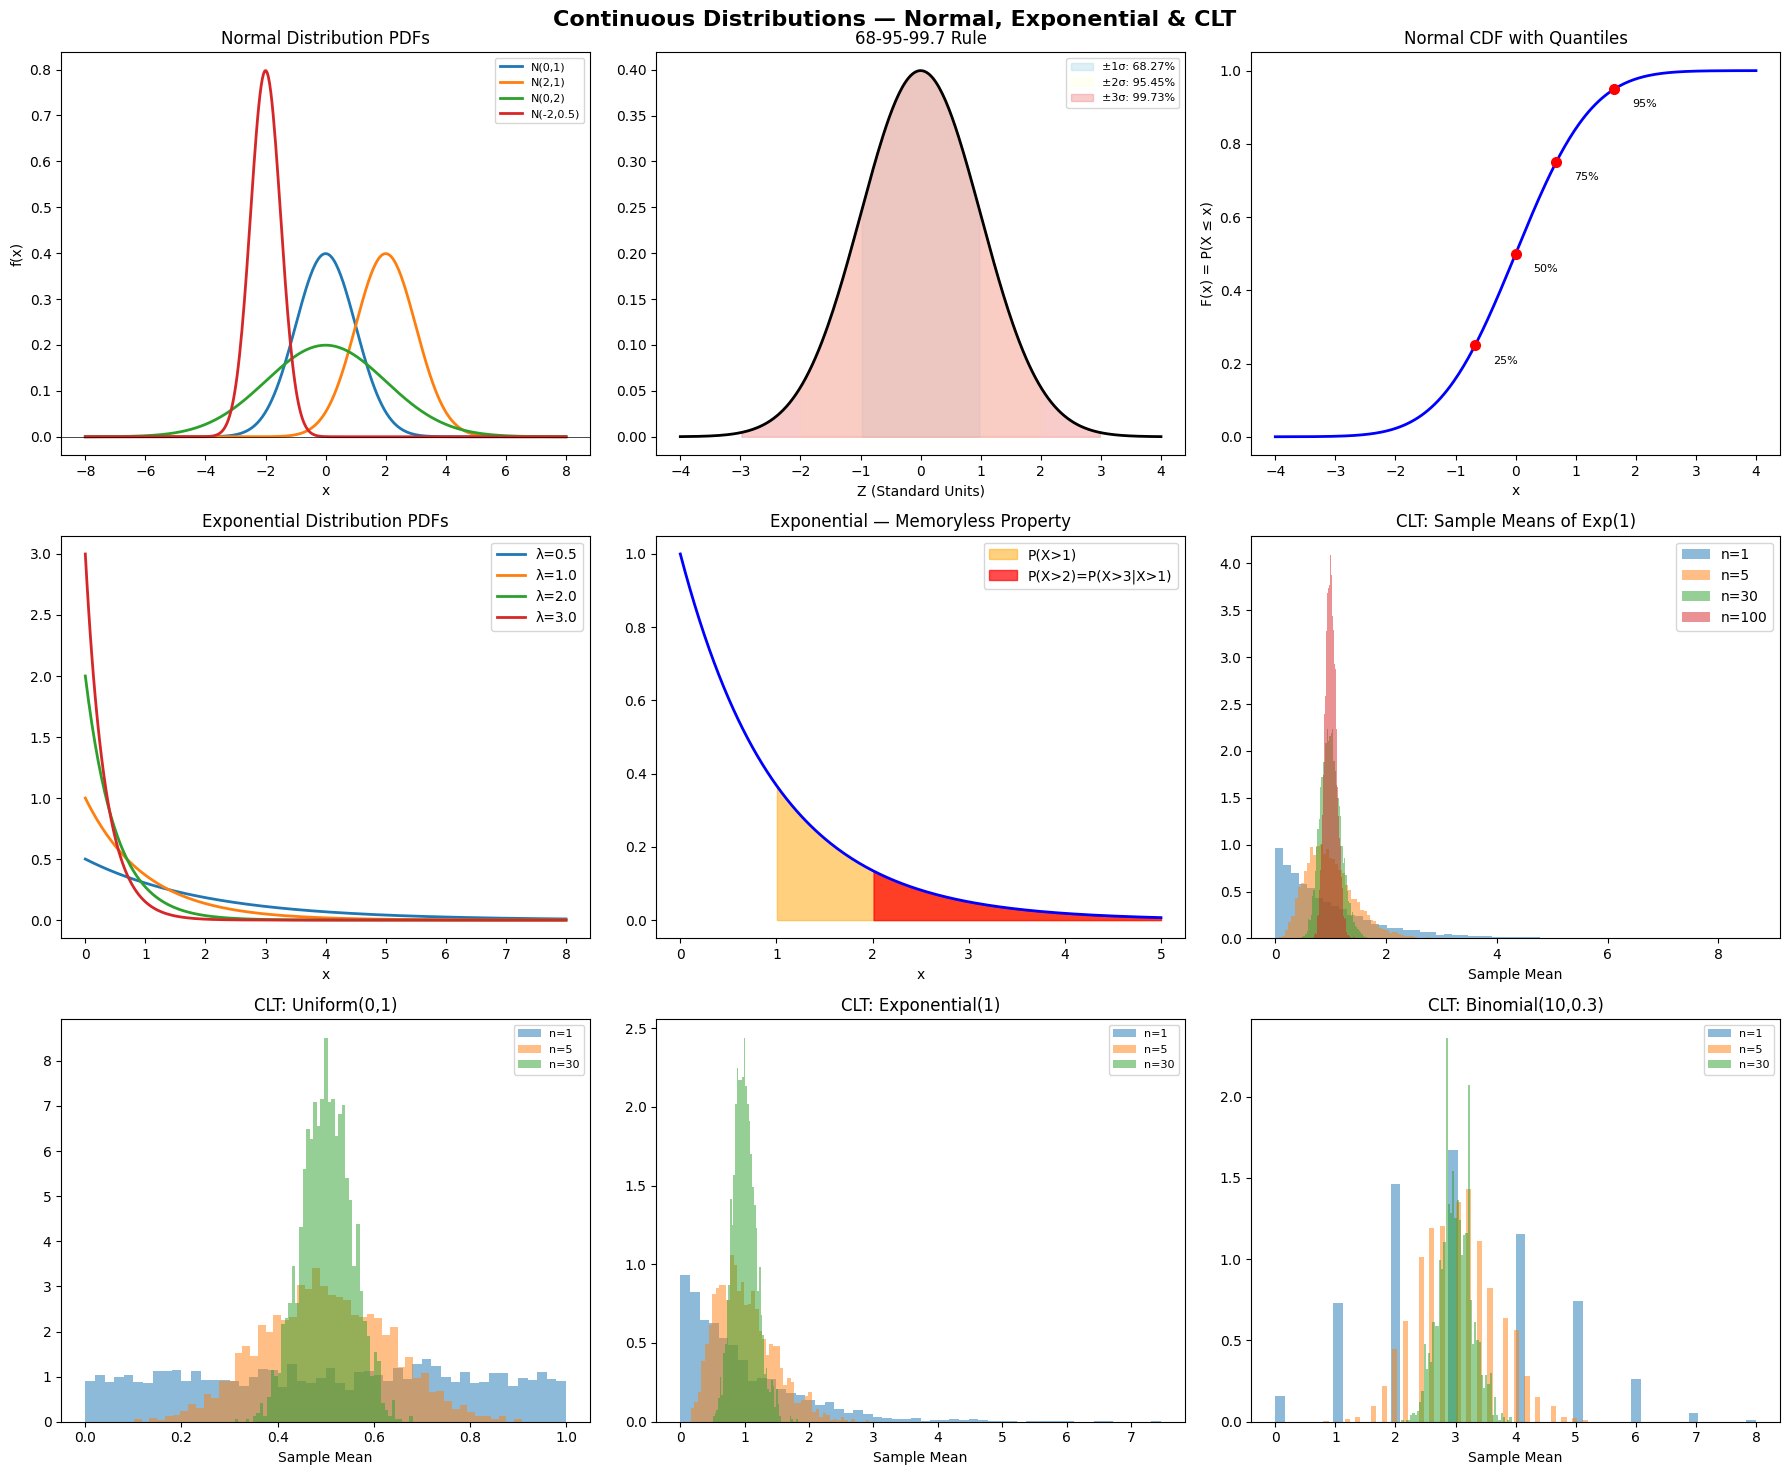


Program 3 Completed Successfully.


In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(18, 15))
fig.suptitle('Continuous Distributions — Normal, Exponential & CLT',
             fontsize=16, fontweight='bold')

# 1. Normal PDFs
for mu, sigma in params:
    axes[0, 0].plot(x, stats.norm.pdf(x, mu, sigma),
                    linewidth=2, label=f'N({mu},{sigma})')
axes[0, 0].set_title('Normal Distribution PDFs')
axes[0, 0].set_xlabel('x')
axes[0, 0].set_ylabel('f(x)')
axes[0, 0].legend(fontsize=8)
axes[0, 0].axhline(0, color='black', linewidth=0.5)

# 2. 68-95-99.7 Rule
x_std = np.linspace(-4, 4, 300)
y_std = stats.norm.pdf(x_std)
axes[0, 1].plot(x_std, y_std, 'k-', linewidth=2)
for interval, color, label in [
        (1, 'lightblue', '68.27%'),
        (2, 'lightyellow', '95.45%'),
        (3, 'lightcoral', '99.73%')]:
    axes[0, 1].fill_between(
        x_std, y_std,
        where=(np.abs(x_std) <= interval),
        alpha=0.4, color=color, label=f'±{interval}σ: {label}')
axes[0, 1].set_title('68-95-99.7 Rule')
axes[0, 1].legend(fontsize=8)
axes[0, 1].set_xlabel('Z (Standard Units)')

# 3. Normal CDF
x_cdf = np.linspace(-4, 4, 300)
axes[0, 2].plot(x_cdf, stats.norm.cdf(x_cdf, 0, 1),
                'blue', linewidth=2)
for q_val in [0.25, 0.50, 0.75, 0.95]:
    q_x = stats.norm.ppf(q_val)
    axes[0, 2].plot(q_x, q_val, 'ro', markersize=7)
    axes[0, 2].annotate(f'{q_val:.0%}',
                        xy=(q_x, q_val),
                        xytext=(q_x+0.3, q_val-0.05),
                        fontsize=8)
axes[0, 2].set_title('Normal CDF with Quantiles')
axes[0, 2].set_xlabel('x')
axes[0, 2].set_ylabel('F(x) = P(X ≤ x)')

# 4. Exponential PDFs
for lam in lambdas_exp:
    axes[1, 0].plot(x_exp, stats.expon.pdf(x_exp, scale=1/lam),
                    linewidth=2, label=f'λ={lam}')
axes[1, 0].set_title('Exponential Distribution PDFs')
axes[1, 0].set_xlabel('x')
axes[1, 0].legend()

# 5. Exponential — Memoryless Property
x_mem = np.linspace(0, 5, 200)
axes[1, 1].fill_between(x_mem, exp_main.pdf(x_mem),
                         where=(x_mem >= 1),
                         alpha=0.5, color='orange',
                         label='P(X>1)')
axes[1, 1].fill_between(x_mem, exp_main.pdf(x_mem),
                         where=(x_mem >= 2),
                         alpha=0.7, color='red',
                         label='P(X>2)=P(X>3|X>1)')
axes[1, 1].plot(x_mem, exp_main.pdf(x_mem), 'b-', linewidth=2)
axes[1, 1].set_title('Exponential — Memoryless Property')
axes[1, 1].legend()
axes[1, 1].set_xlabel('x')

# 6. CLT for different sample sizes
clt_data = np.random.exponential(1, (100, 10000))
for i, n in enumerate([1, 5, 30, 100]):
    means = clt_data[:n, :].mean(axis=0)
    axes[1, 2].hist(means, bins=60, density=True, alpha=0.5,
                    label=f'n={n}')
axes[1, 2].set_title('CLT: Sample Means of Exp(1)')
axes[1, 2].set_xlabel('Sample Mean')
axes[1, 2].legend()

# 7-9: CLT for different distributions
for idx, (dist_name, sampler) in enumerate(
        distributions_clt.items()):
    ax = axes[2, idx]
    for n in [1, 5, 30]:
        sample_means = [np.mean(sampler(n)) for _ in range(2000)]
        ax.hist(sample_means, bins=50, density=True,
                alpha=0.5, label=f'n={n}')
    ax.set_title(f'CLT: {dist_name}')
    ax.set_xlabel('Sample Mean')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('P3_continuous_distributions.png', dpi=150,
            bbox_inches='tight')
plt.show()
print("\nProgram 3 Completed Successfully.")



Student Result: PASS
Model Accuracy: 100.0 %


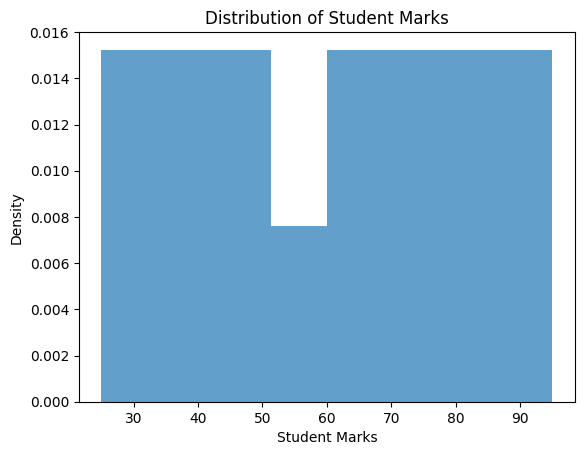

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Sample dataset: Student marks
X = np.array([
    [25], [30], [35], [40], [45],
    [50], [55], [60], [65], [70],
    [75], [80], [85], [90], [95]
])

# 0 = Fail, 1 = Pass
y = np.array([
    0, 0, 0, 0, 0,
    0, 1, 1, 1, 1,
    1, 1, 1, 1, 1
])

# Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train the Gaussian Naive Bayes model
model = GaussianNB()
model.fit(X_train, y_train)

# Predict the result for a student scoring 68 marks
marks = np.array([[68]])
prediction = model.predict(marks)

if prediction[0] == 1:
    print("Student Result: PASS")
else:
    print("Student Result: FAIL")

# Evaluate the model
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Plot the normal distribution of sample marks
plt.hist(X.flatten(), bins=8, density=True, alpha=0.7)
plt.xlabel("Student Marks")
plt.ylabel("Density")
plt.title("Distribution of Student Marks")
plt.show()

Weather: Suitable for outdoor activities


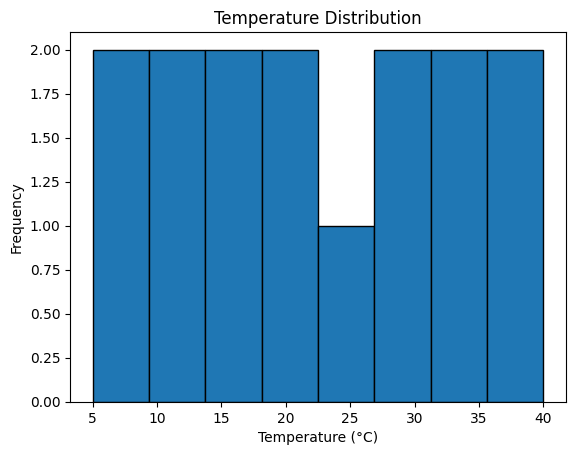

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB

# Training data: Temperature in Celsius
X = np.array([
    [5], [8], [10], [12], [15],
    [18], [20], [22], [25], [28],
    [30], [32], [35], [38], [40]
])

# 0 = Not Suitable, 1 = Suitable
y = np.array([
    0, 0, 0, 0, 0,
    1, 1, 1, 1, 1,
    1, 1, 1, 0, 0
])

# Create and train the model
model = GaussianNB()
model.fit(X, y)

# Predict suitability at 26°C
temperature = np.array([[26]])
prediction = model.predict(temperature)

if prediction[0] == 1:
    print("Weather: Suitable for outdoor activities")
else:
    print("Weather: Not suitable for outdoor activities")

# Plot temperature distribution
plt.hist(X.flatten(), bins=8, edgecolor="black")
plt.xlabel("Temperature (°C)")
plt.ylabel("Frequency")
plt.title("Temperature Distribution")
plt.show()

🌦️ WEATHER PREDICTION
----------------------------
Temperature: 26 °C
Prediction: Suitable for outdoor activities


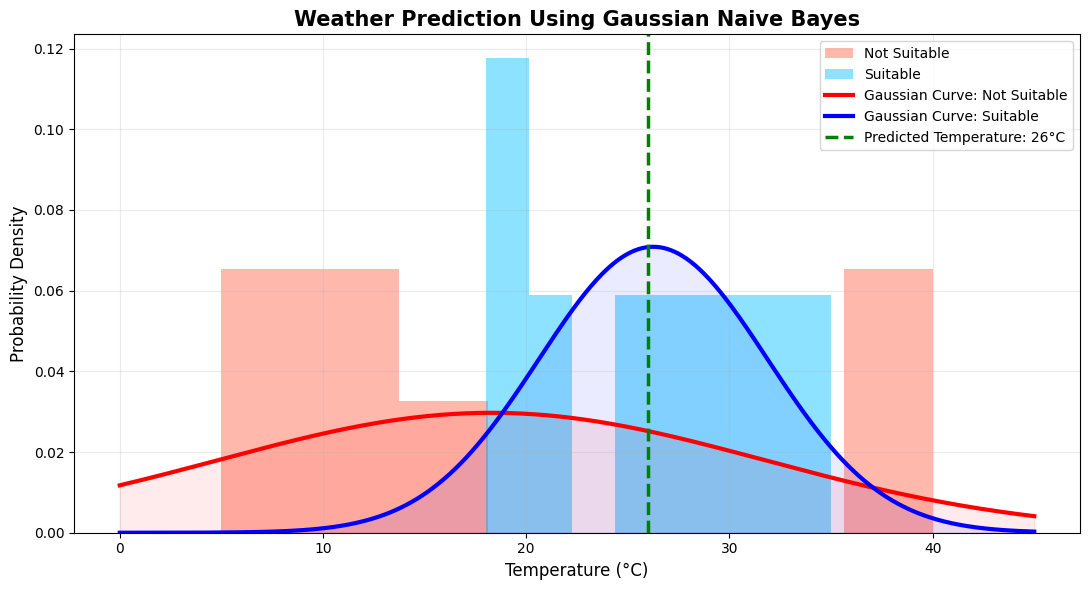

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB
from scipy.stats import norm

# Training data: Temperature in Celsius
X = np.array([
    [5], [8], [10], [12], [15],
    [18], [20], [22], [25], [28],
    [30], [32], [35], [38], [40]
])

# 0 = Not Suitable, 1 = Suitable
y = np.array([
    0, 0, 0, 0, 0,
    1, 1, 1, 1, 1,
    1, 1, 1, 0, 0
])

# Train the ML model
model = GaussianNB()
model.fit(X, y)

# Predict weather suitability at 26°C
temperature = np.array([[26]])
prediction = model.predict(temperature)

print("🌦️ WEATHER PREDICTION")
print("----------------------------")
print("Temperature:", temperature[0][0], "°C")
print("Prediction:",
      "Suitable for outdoor activities"
      if prediction[0] == 1
      else "Not suitable for outdoor activities")

# Prepare graph data
temps = np.linspace(0, 45, 500)

# Calculate Gaussian curves for each class
mean_0 = model.theta_[0][0]
std_0 = np.sqrt(model.var_[0][0])

mean_1 = model.theta_[1][0]
std_1 = np.sqrt(model.var_[1][0])

curve_0 = norm.pdf(temps, mean_0, std_0)
curve_1 = norm.pdf(temps, mean_1, std_1)

# Create a colourful graph
plt.figure(figsize=(11, 6))

# Plot temperature data
plt.hist(
    X[y == 0].flatten(),
    bins=8,
    density=True,
    alpha=0.45,
    color="tomato",
    label="Not Suitable"
)

plt.hist(
    X[y == 1].flatten(),
    bins=8,
    density=True,
    alpha=0.45,
    color="deepskyblue",
    label="Suitable"
)

# Plot Gaussian distribution curves
plt.plot(
    temps, curve_0,
    color="red",
    linewidth=3,
    label="Gaussian Curve: Not Suitable"
)

plt.plot(
    temps, curve_1,
    color="blue",
    linewidth=3,
    label="Gaussian Curve: Suitable"
)

# Mark predicted temperature
plt.axvline(
    26,
    color="green",
    linestyle="--",
    linewidth=2.5,
    label="Predicted Temperature: 26°C"
)

plt.fill_between(
    temps, curve_0,
    color="red",
    alpha=0.08
)

plt.fill_between(
    temps, curve_1,
    color="blue",
    alpha=0.08
)

# Graph styling
plt.title(
    "Weather Prediction Using Gaussian Naive Bayes",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Temperature (°C)", fontsize=12)
plt.ylabel("Probability Density", fontsize=12)

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()
